# Bagging et Random Forest : comprendre pourquoi ça marche

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/bagging/bagging.ipynb)

📖 **Le mini-cours complet** : [Comprendre enfin pourquoi le bagging marche (et pas seulement comment)](https://www.monshotdata.com/p/bagging)

🧭 **Le cours** : [ML classique et Deep Learning › 2.1 Fondations mathématiques](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc21)

---

Un arbre de décision seul surapprend toujours. Mais **plusieurs arbres décorrélés**, moyennés, font bien mieux : c'est le bagging, et c'est le cœur de la Random Forest. Dans ce notebook, tu vas d'abord *voir* le surapprentissage, puis *démontrer* pourquoi la corrélation entre modèles est le vrai ennemi, et enfin **coder toi-même une Random Forest**.

**À la fin de ce notebook, tu sauras :**

- voir et comparer le surapprentissage d'un arbre, d'une régression linéaire et d'une régression polynomiale ;
- comprendre pourquoi moyenner des modèles réduit l'erreur, mais seulement s'ils sont peu corrélés ;
- coder à la main le bootstrapping et le vote majoritaire, et comparer ta forêt à celle de scikit-learn.


### Avant de lancer

Aucun fichier externe, aucun GPU : **Exécution → Tout exécuter** (environ 15 secondes). La police *Comic Sans MS* n'est pas installée sur Colab : Matplotlib utilise alors une police de secours, sans incidence sur les résultats.

Les exercices se trouvent dans le notebook `bagging-exercice.ipynb`.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, NumPy, pandas, scikit-learn et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

In [1]:
import seaborn as sns

sns.set()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression

import warnings
warnings.filterwarnings("ignore")

In [2]:
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # évite les avertissements si la police n'est pas installée

plt.rcParams['font.family'] = ['Comic Sans MS', 'sans-serif']

colors = ['#fe7c73', '#2471A3']

## 2. L'expérience de surapprentissage

On génère des données bruitées : une tendance linéaire (y = 2x) plus une oscillation (sinus) plus du bruit. On n'en garde que quelques points pour l'entraînement, et on regarde comment trois modèles se comportent.

### 2.1 Générer le dataset

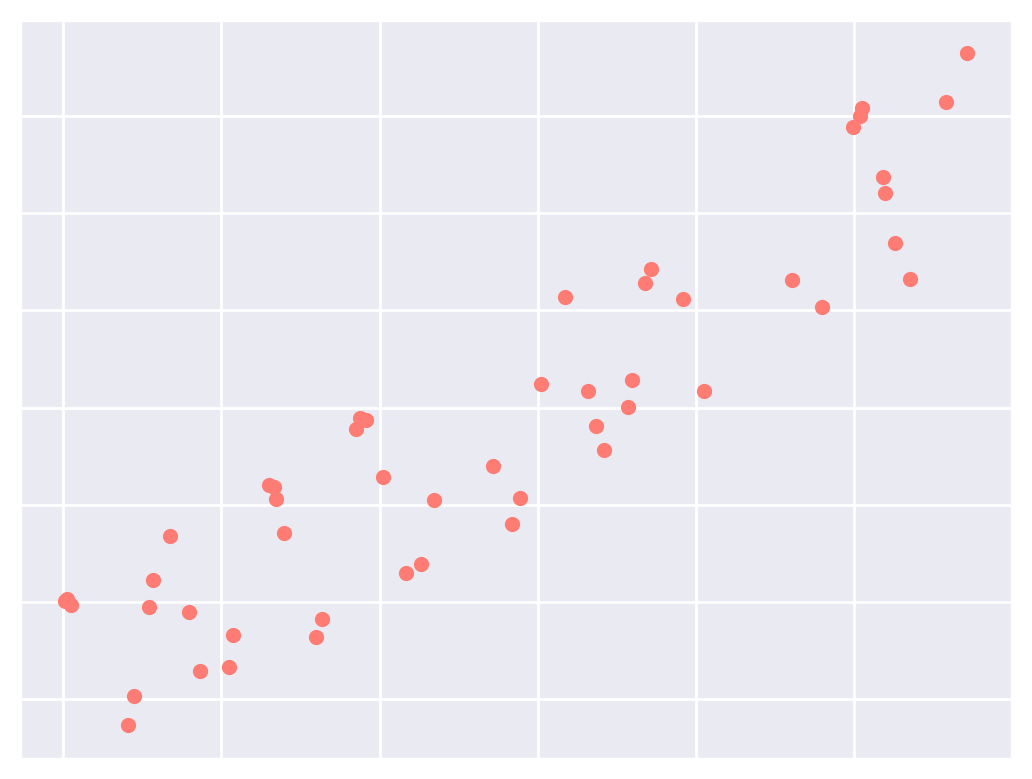

In [3]:
X = np.linspace(-3, 3, 500).reshape(-1, 1)
y = 2*X + 2*np.sin(X*10) + np.random.normal(0, 0.1, X.shape[0]).reshape(-1, 1)

num_samples = 50  # Tu peux modifier cette valeur selon le nombre d'échantillons souhaité
random_indices = np.random.choice(len(X), num_samples, replace=False)

# Échantillonner les points correspondants des deux tableaux en utilisant les indices aléatoires
sampled_array1 = X[random_indices]
sampled_array2 = y[random_indices]

sampled_array2 = sampled_array2[sampled_array1.argsort(0)].squeeze().reshape(-1, 1)
sampled_array1 = sampled_array1[sampled_array1.argsort(0)].squeeze().reshape(-1, 1)

fig, ax = plt.subplots()

ax.scatter(sampled_array1, sampled_array2, label='Données', color=colors[0], s=20)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

### 2.2 Un arbre de décision surapprend

Sans contrainte de profondeur, l'arbre colle exactement à chaque point d'entraînement : erreur nulle sur l'entraînement, mais une courbe en escaliers qui épouse le bruit.

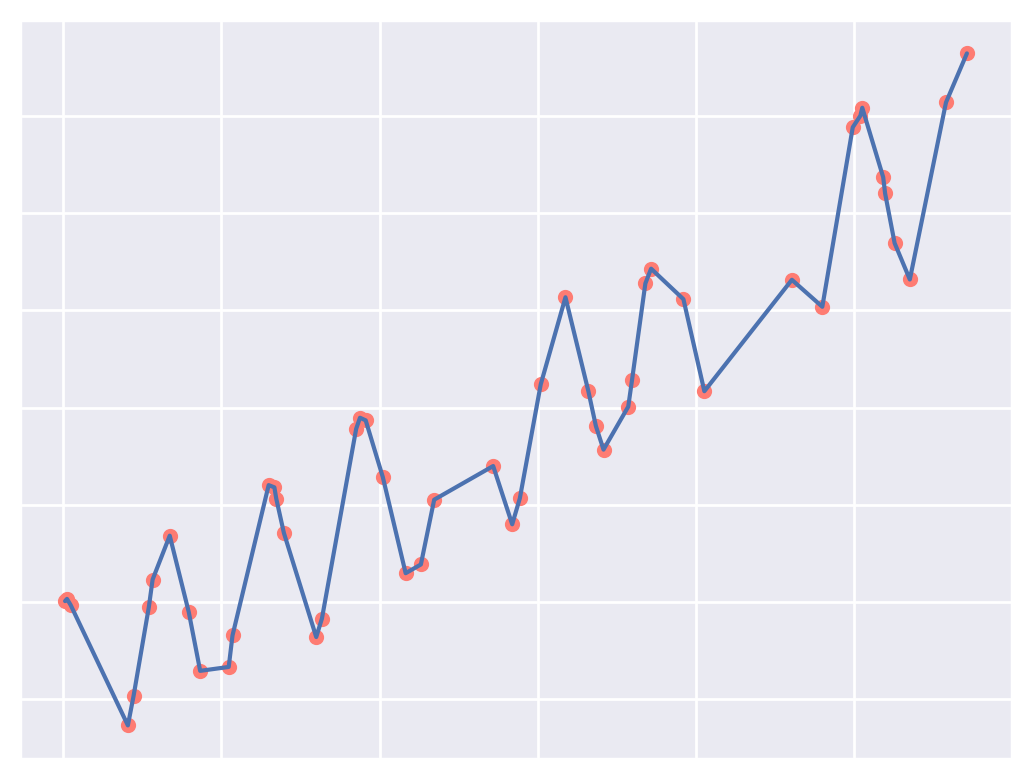

In [4]:
tree_model = DecisionTreeRegressor().fit(sampled_array1, sampled_array2)

fig, ax = plt.subplots()

ax.scatter(sampled_array1, sampled_array2, label='Données', color=colors[0], s=20)
ax.plot(sampled_array1, tree_model.predict(sampled_array1))
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

### 2.3 La régression linéaire, à l'opposé

Elle est trop rigide pour suivre l'oscillation : c'est le sous-apprentissage. Le surapprentissage n'est donc pas réservé aux modèles « complexes ».

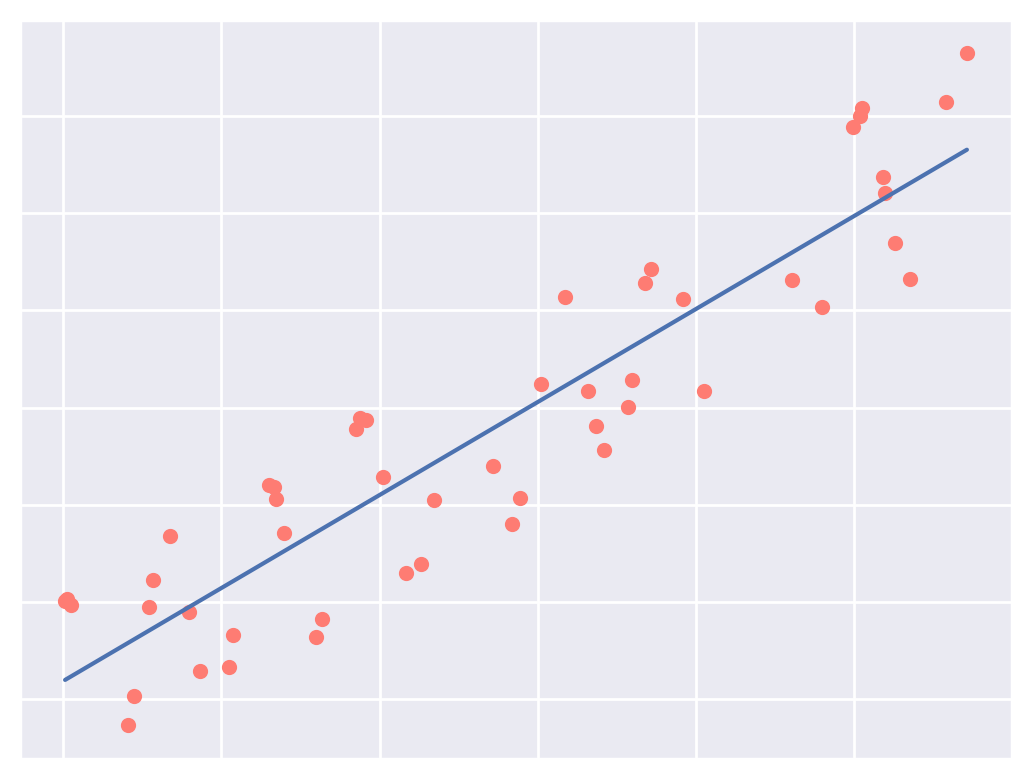

In [5]:
lr_model = LinearRegression().fit(sampled_array1, sampled_array2)

fig, ax = plt.subplots()

ax.scatter(sampled_array1, sampled_array2, label='Données', color=colors[0], s=20)
ax.plot(sampled_array1, lr_model.predict(sampled_array1))
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

### 2.4 La régression polynomiale : du sous-apprentissage au surapprentissage

En augmentant le degré du polynôme (1, 2, 5, 10, 20, 40), on passe progressivement d'une droite trop simple à une courbe qui s'agite pour passer par tous les points.

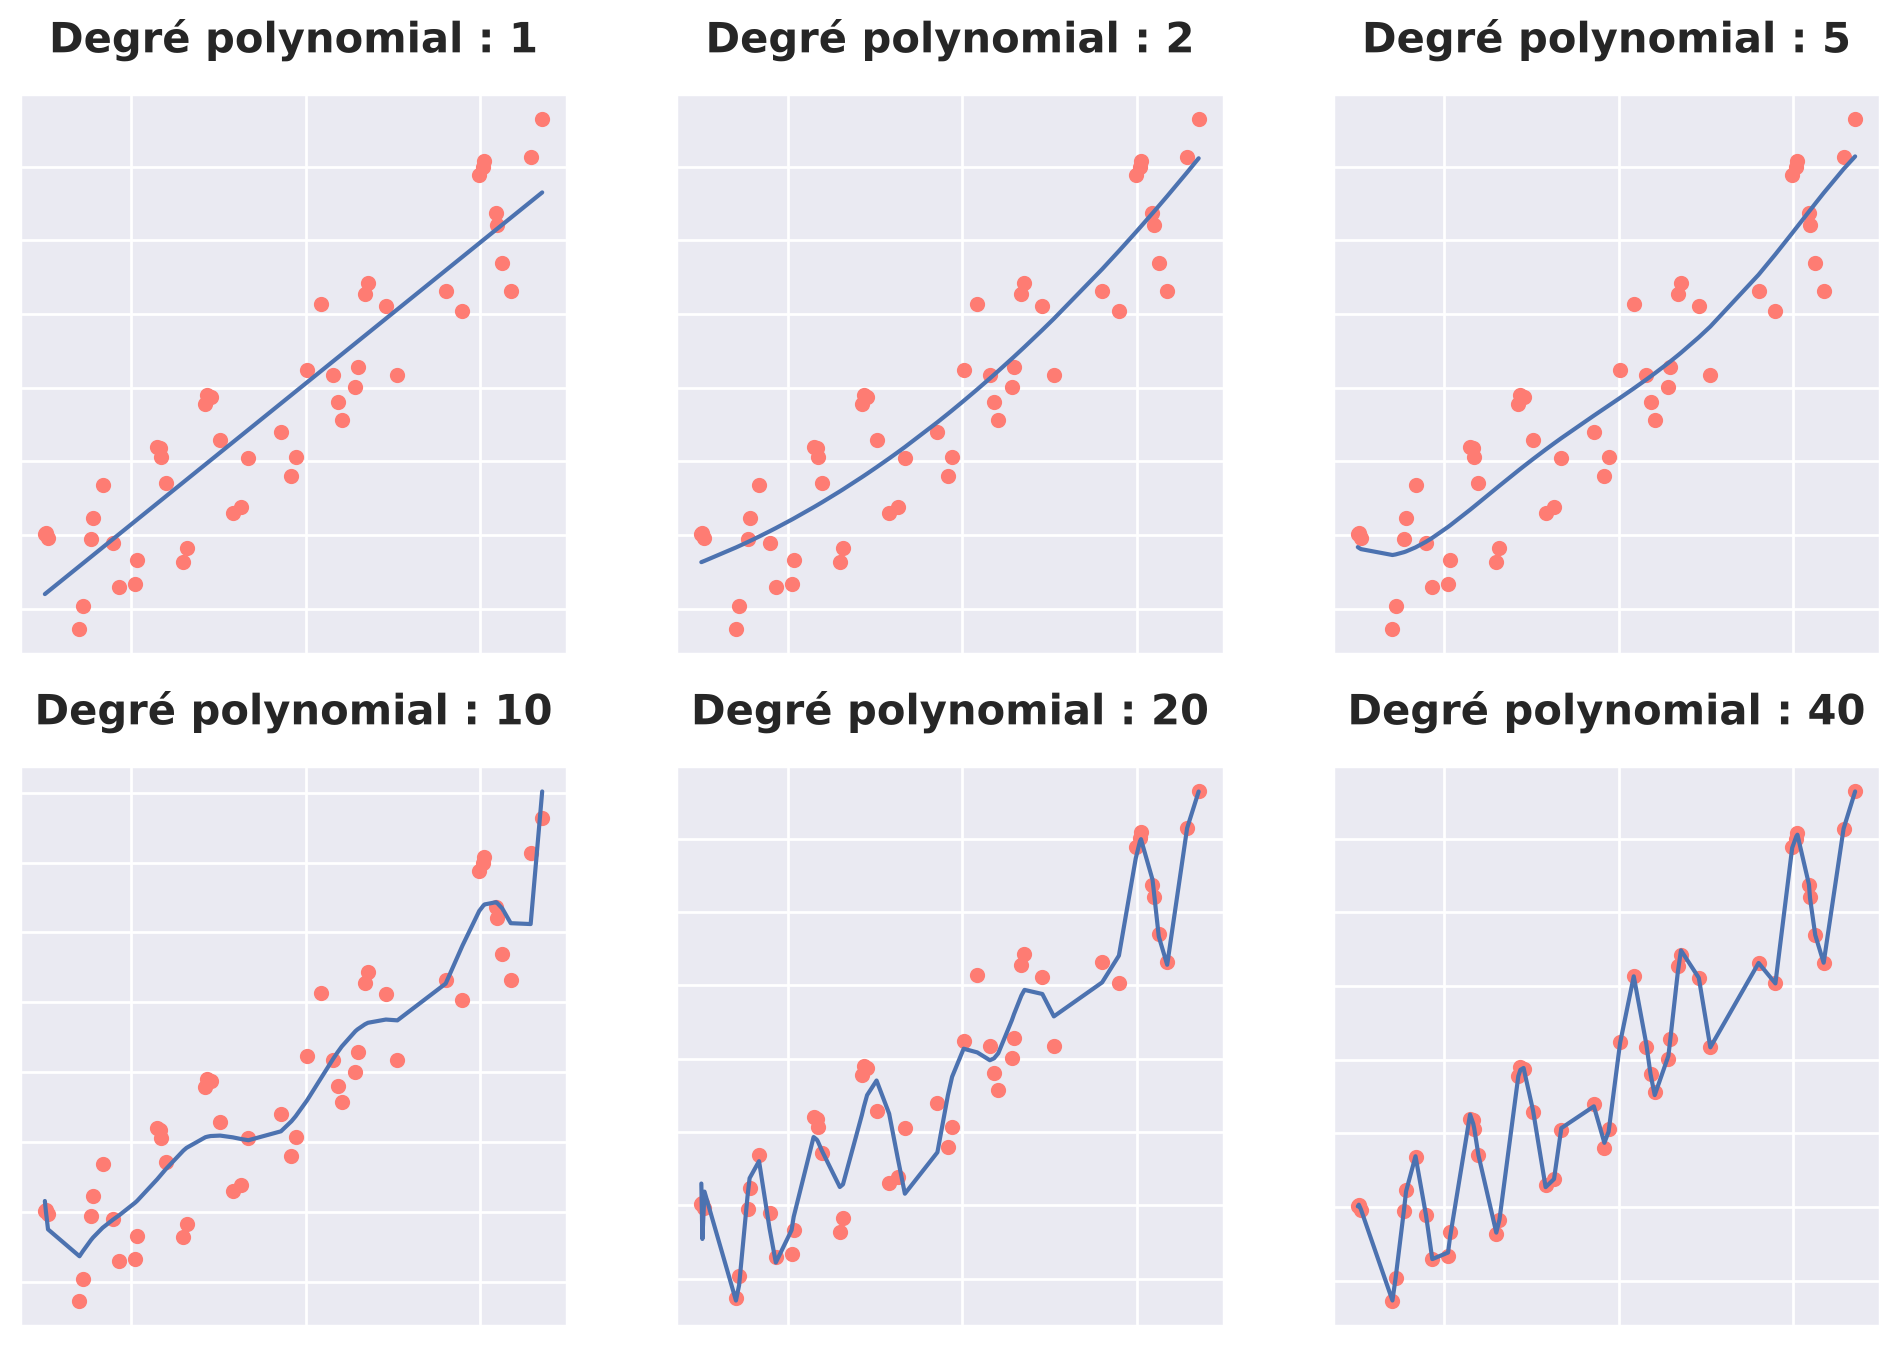

In [6]:
fig, ax = plt.subplot_mosaic("ABC;DEF", figsize=(12, 8))
degrees = [1, 2, 5, 10, 20, 40]

for degree, key in zip(degrees, ax.keys()):

    # Créer un modèle de régression polynomiale
    coeff = np.polyfit(sampled_array1.reshape(-1), sampled_array2, deg=degree).reshape(-1)
    lr_model2 = np.poly1d(coeff)

    ax[key].scatter(sampled_array1, sampled_array2, label='Données', color=colors[0], s=20)
    ax[key].plot(sampled_array1, lr_model2(sampled_array1))
    ax[key].set_xticklabels([])
    ax[key].set_yticklabels([])
    ax[key].set_title(f"Degré polynomial : {degree}", fontsize=15, weight="bold", pad=15)

plt.show()

## 3. Vers la Random Forest

Le bagging répond au surapprentissage des arbres en entraînant **plusieurs arbres sur des versions bootstrap des données** et en agrégeant leurs prédictions.

### 3.1 Un dataset de classification en 2D

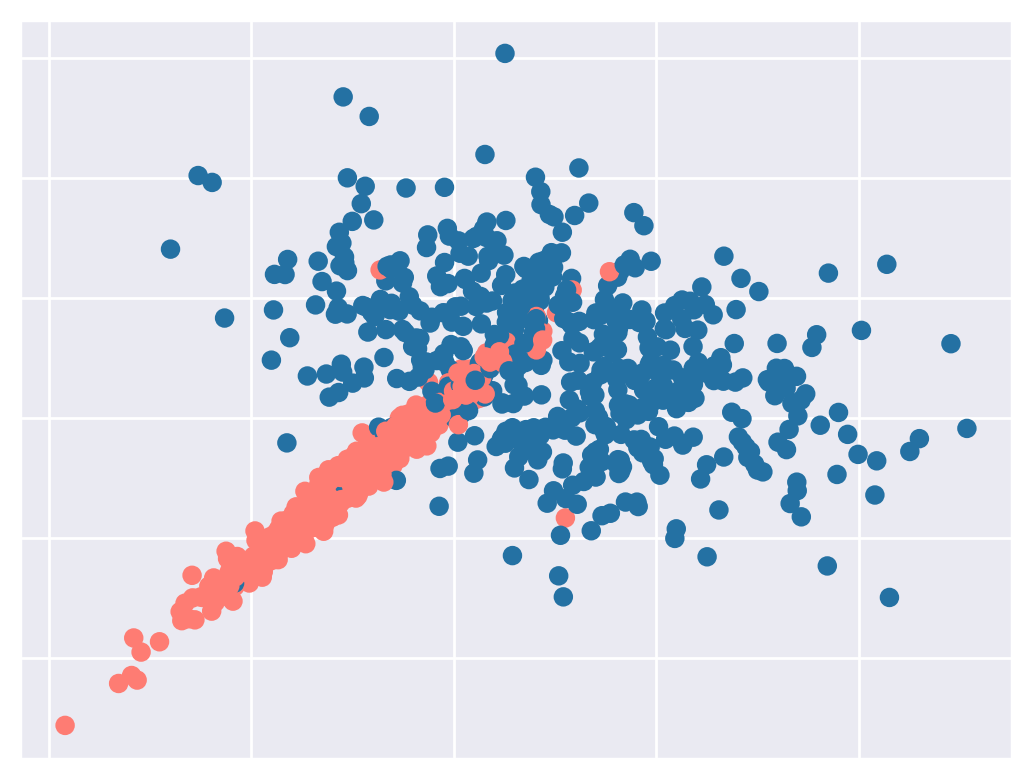

In [7]:
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_clusters_per_class=1,
    n_informative=2, class_sep=0.5,
    n_redundant=0,
    n_repeated=0
)

fig, ax = plt.subplots()
plt.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in y])
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

### 3.2 Arbre de décision vs Random Forest

On compare les régions de décision : l'arbre découpe le plan en rectangles très irréguliers, la forêt lisse la frontière.

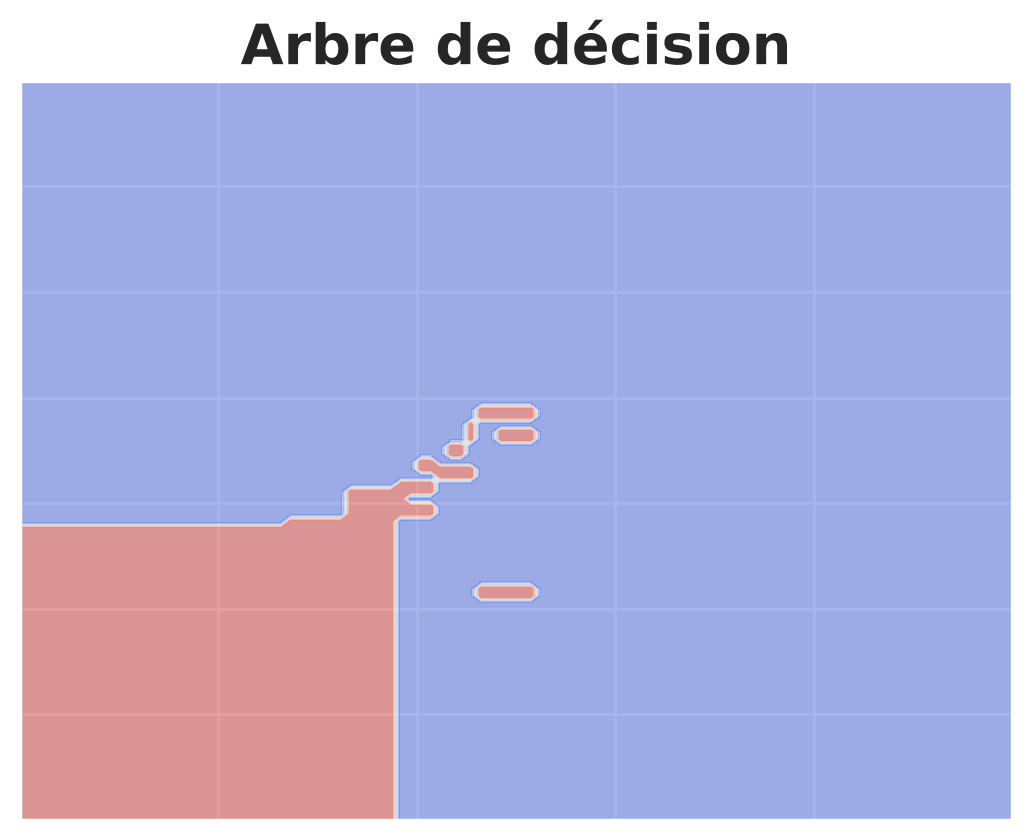

In [8]:
# Entraînement
dtree = DecisionTreeClassifier(random_state=0)
dtree.fit(X, y)

# Graphique des régions de décision
xx, yy = np.meshgrid(np.linspace(np.floor(X[:, 0].min()), np.ceil(X[:, 0].max()), 100), np.linspace(np.floor(X[:, 1].min()), np.ceil(X[:, 1].max()), 100))
Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
plt.contourf(xx, yy, Z, alpha=0.5, cmap='coolwarm_r')
ax.set_title("Arbre de décision", fontsize = 20, fontweight = "bold")
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

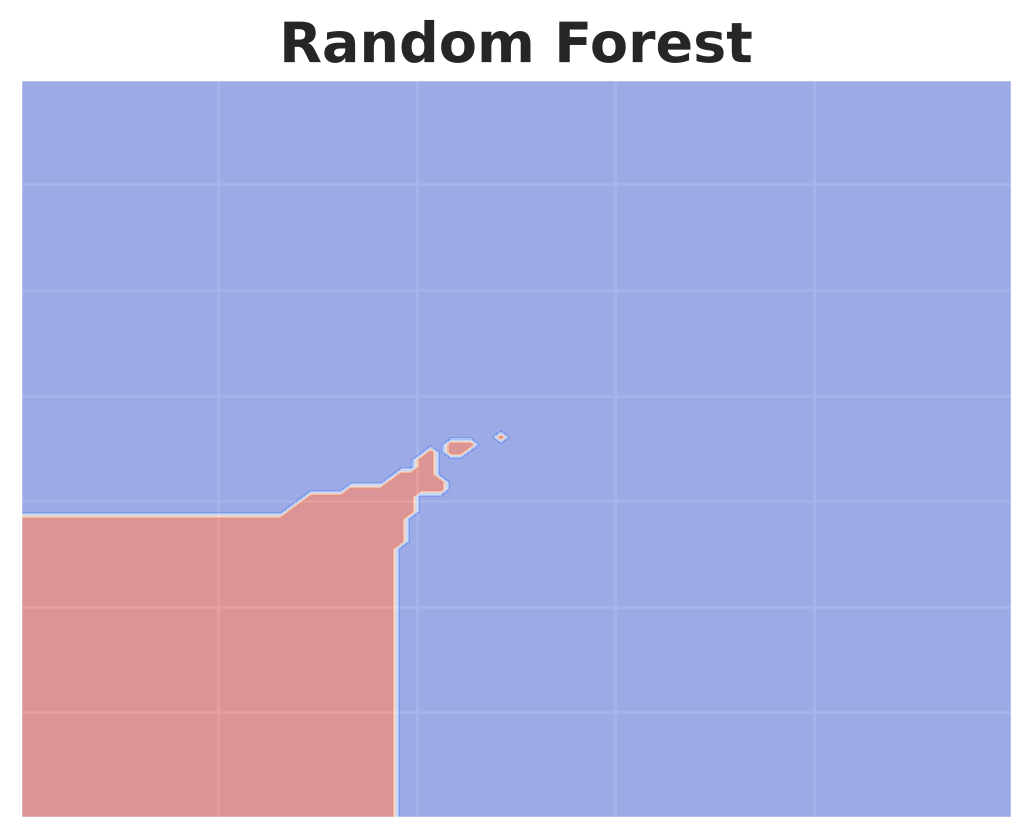

In [9]:
# Entraîner le modèle Random Forest
rfmodel = RandomForestClassifier(random_state=0)
rfmodel.fit(X, y)

# Graphique des régions de décision
xx, yy = np.meshgrid(np.linspace(np.floor(X[:, 0].min()), np.ceil(X[:, 0].max()), 100), np.linspace(np.floor(X[:, 1].min()), np.ceil(X[:, 1].max()), 100))
Z = rfmodel.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
plt.contourf(xx, yy, Z, alpha=0.5, cmap='coolwarm_r')
ax.set_title("Random Forest", fontsize = 20, fontweight = "bold")
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

### 3.3 La corrélation ne dépend pas de l'échelle

Petite preuve numérique utile pour la suite du mini-cours : multiplier deux variables par le même facteur ne change pas leur corrélation. La corrélation mesure la *forme* de la relation, pas la *taille* des valeurs.

In [10]:
size = 100

X = 10*np.random.rand(size)  # Variable d'origine X
Y = 2 * X + 5*np.random.random(size)  # Variable d'origine Y (avec une relation linéaire)

# Calculer la corrélation avant mise à l'échelle
correlation_before_scaling = np.corrcoef(X, Y)[0, 1]

# Mettre à l'échelle les deux variables de manière égale
scaling_factor = 1/5
X_scaled = X * scaling_factor
Y_scaled = Y * scaling_factor

# Calculer la corrélation après mise à l'échelle
correlation_after_scaling = np.corrcoef(X_scaled, Y_scaled)[0, 1]

print(f"Corrélation avant mise à l'échelle : {correlation_before_scaling:.2f}")
print(f"Corrélation après mise à l'échelle : {correlation_after_scaling:.2f}")

Corrélation avant mise à l'échelle : 0.96
Corrélation après mise à l'échelle : 0.96


## 4. Une Random Forest codée à la main

On recrée l'idée du bootstrapping : tirer avec remise des lignes du jeu d'entraînement pour fabriquer des datasets différents, entraîner un arbre sur chacun, puis faire voter les arbres.

### 4.1 La fonction de bootstrapping

On tire d'abord une fraction `initial_sample_ratio` des lignes, puis on complète en dupliquant au hasard des lignes de cet échantillon jusqu'à atteindre `final_size`.

In [11]:
def sampling_function(df, final_size, initial_sample_ratio):

    total_samples = df.shape[0]
    initial_sample_size = int(initial_sample_ratio*total_samples)

    initial_sample_df = df.sample(initial_sample_size)

    sampled_rows = pd.DataFrame()

    remaining_rows = final_size - initial_sample_size
    for i in range(remaining_rows):
        sampled_row = initial_sample_df.sample(1)

        sampled_rows = pd.concat((sampled_rows, sampled_row))

    bootstrapped_dataset = pd.concat((initial_sample_df, sampled_rows))
    return bootstrapped_dataset

### 4.2 La fonction de prédiction

Chaque arbre prédit, puis on retient la classe la plus fréquente (**vote majoritaire**).

In [12]:
from collections import Counter

def predict(models, test_data):
    # En supposant que vous avez des données de test 'X_test' sous forme de DataFrame
    predictions = []

    # Faire des prédictions en utilisant chaque arbre dans 'all_trees'
    for model in models:
        model_predictions = model.predict(test_data)
        predictions.append(model_predictions)

    # Effectuer un vote majoritaire pour agréger les prédictions
    ensemble_predictions = []
    for i in range(len(test_data)):
        ensemble_prediction = Counter([prediction[i] for prediction in predictions]).most_common(1)[0][0]
        ensemble_predictions.append(ensemble_prediction)

    ensemble_predictions = np.array(ensemble_predictions)

    return ensemble_predictions

### 4.3 Les données de comparaison

On génère un jeu de classification synthétique et on le sépare en entraînement (1000 points) et test (200 points).

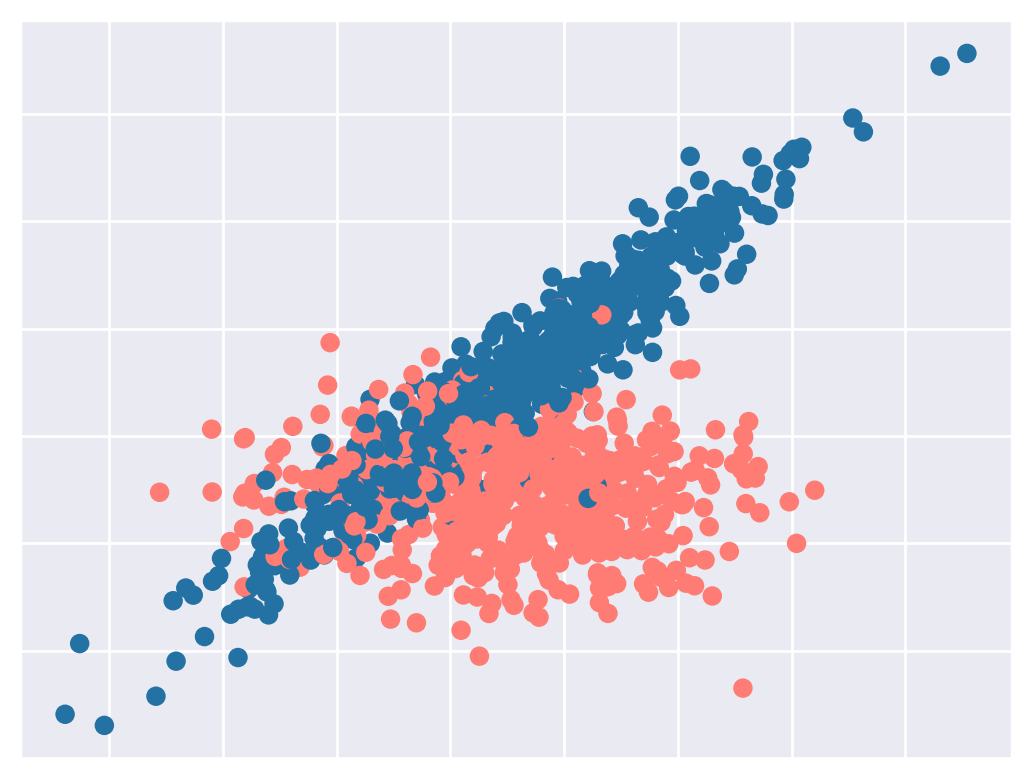

In [13]:
# Générer des données synthétiques pour entraîner l'arbre de décision
X, y = make_classification(
    n_samples=1200,
    n_features=2,
    n_clusters_per_class=1,
    n_informative=2, class_sep=0.5,
    n_redundant=0,
    n_repeated=0
)

fig, ax = plt.subplots()
plt.scatter(X[:, 0], X[:, 1], c=[colors[i] for i in y])
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

X_train, y_train = X[:1000], y[:1000]
X_test, y_test = X[1000:], y[1000:]

### 4.4 Les modèles de référence : arbre seul et Random Forest de scikit-learn

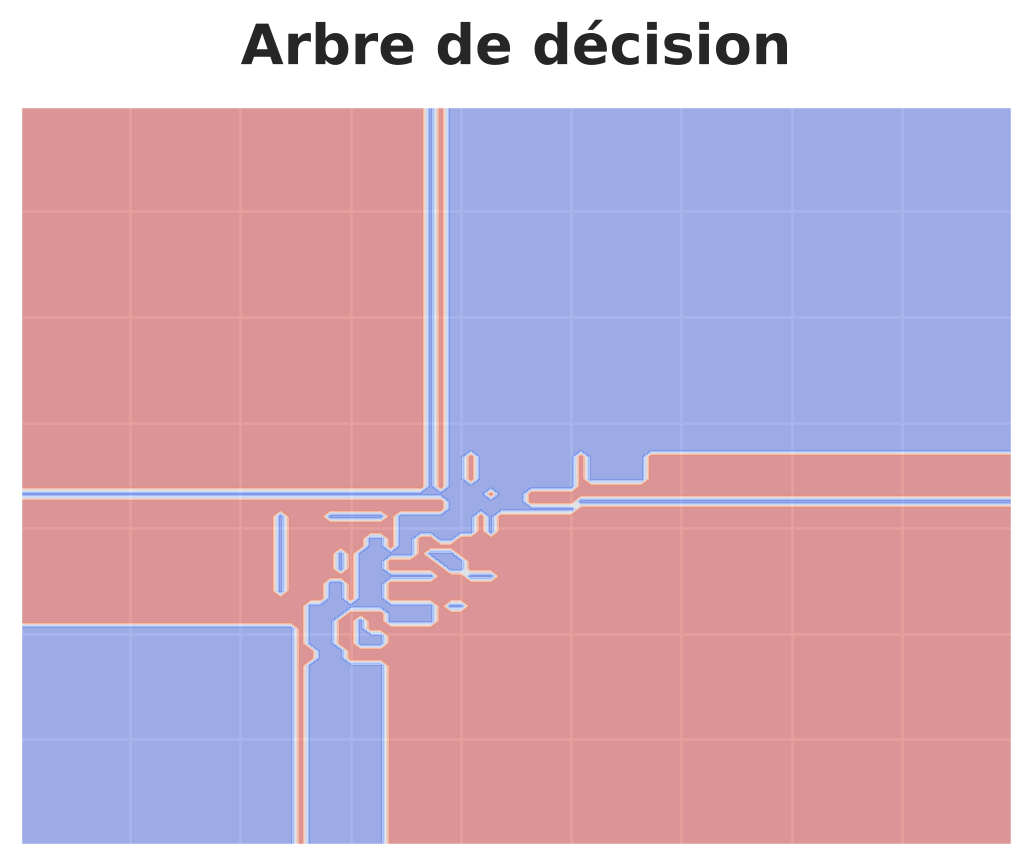

0.79

In [14]:
dtree = DecisionTreeClassifier(random_state=0)
dtree.fit(X_train, y_train)

xx, yy = np.meshgrid(np.linspace(np.floor(X_train[:, 0].min()), np.ceil(X_train[:, 0].max()), 100), np.linspace(np.floor(X_train[:, 1].min()), np.ceil(X_train[:, 1].max()), 100))
Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
plt.contourf(xx, yy, Z, alpha=0.5, cmap='coolwarm_r')
ax.set_title("Arbre de décision", fontsize = 20, fontweight = "bold", pad=15)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

dtree.score(X_test, y_test)

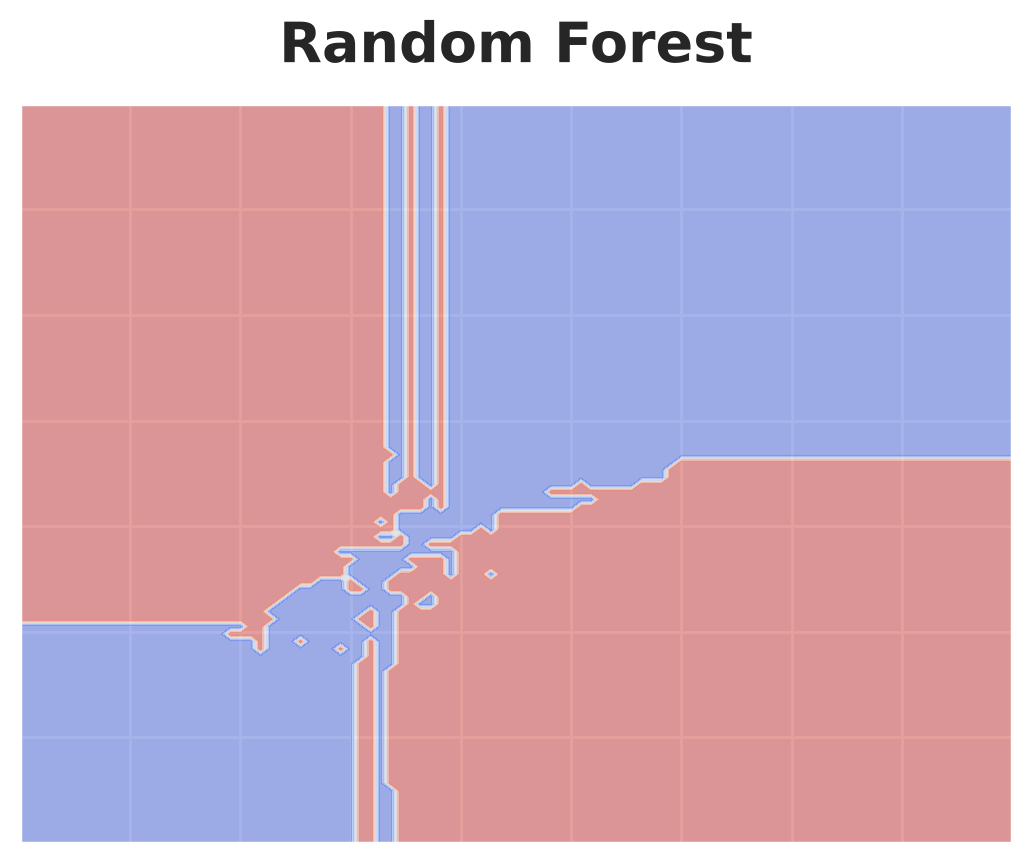

0.815

In [15]:
rfmodel = RandomForestClassifier(max_features="sqrt", max_samples=0.5, n_estimators=21)
rfmodel.fit(X_train, y_train)

xx, yy = np.meshgrid(np.linspace(np.floor(X_train[:, 0].min()), np.ceil(X_train[:, 0].max()), 100), np.linspace(np.floor(X_train[:, 1].min()), np.ceil(X_train[:, 1].max()), 100))
Z = rfmodel.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
plt.contourf(xx, yy, Z, alpha=0.5, cmap='coolwarm_r')
ax.set_title("Random Forest", fontsize = 20, fontweight = "bold", pad=15)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

rfmodel.score(X_test, y_test)

### 4.5 Notre Random Forest

On met les données sous forme de DataFrame, puis on entraîne 21 arbres, chacun sur un échantillon bootstrap différent.

In [16]:
df_train = pd.DataFrame()
df_test = pd.DataFrame()

df_train[["X1", "X2"]] = X_train
df_train["y"] = y_train

df_test[["X1", "X2"]] = X_test
df_test["y"] = y_test

In [17]:
total_models = 21
final_size = 2*df_train.shape[0]
initial_sample_ratio = 0.5

all_trees = []

for i in range(total_models):
    model = DecisionTreeClassifier(max_features="sqrt")
    data = sampling_function(df_train, final_size, initial_sample_ratio)

    model.fit(data[["X1", "X2"]], data['y'])

    all_trees.append(model)

### 4.6 Agréger les prédictions et comparer

On trace la frontière de décision de notre forêt, puis on compare les trois modèles sur le jeu de test. Les données étant tirées au hasard à chaque exécution, les trois précisions varient d'un lancement à l'autre : relance la cellule de génération des données puis celles qui suivent pour voir la tendance. Notre forêt « maison » reste proche de celle de scikit-learn ; les deux produisent surtout une frontière de décision plus lisse que celle de l'arbre seul.

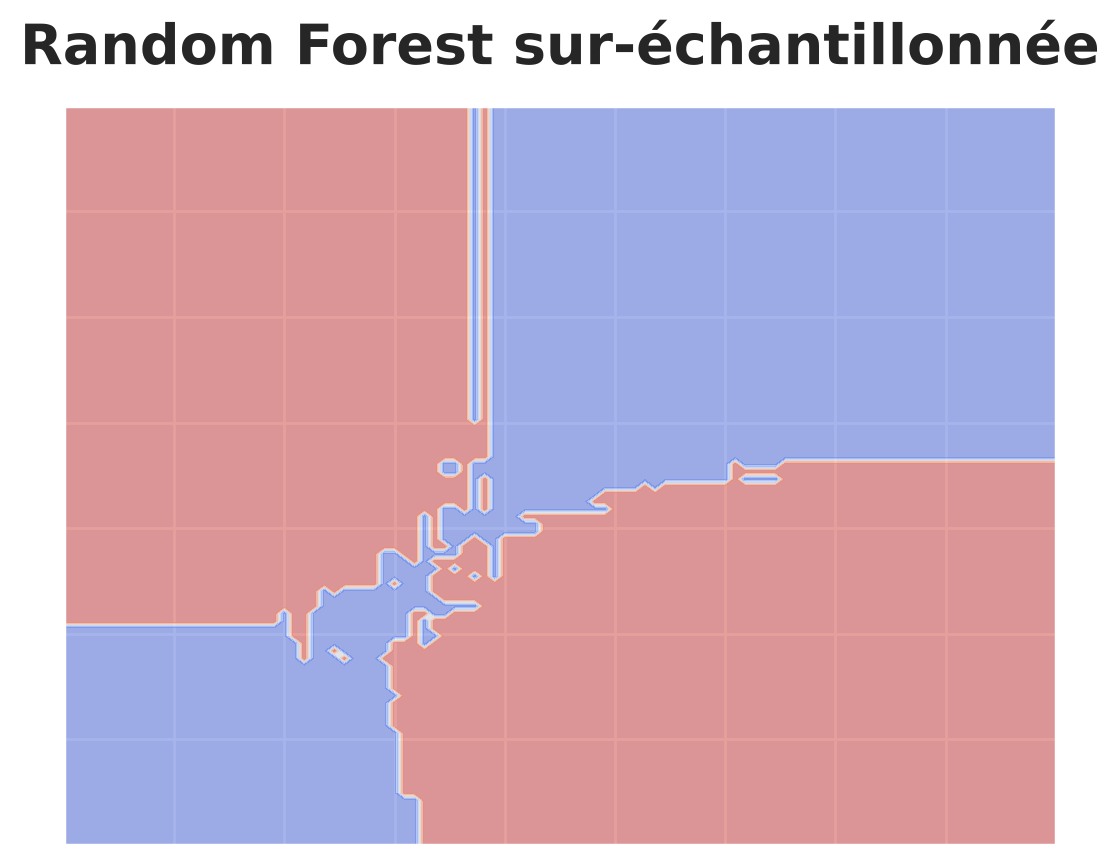

0.805

In [18]:
xx, yy = np.meshgrid(np.linspace(np.floor(X_train[:, 0].min()), np.ceil(X_train[:, 0].max()), 100), np.linspace(np.floor(X_train[:, 1].min()), np.ceil(X_train[:, 1].max()), 100))

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=["X1", "X2"]
)

Z = predict(all_trees, grid)
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots()
plt.contourf(xx, yy, Z, alpha=0.5, cmap='coolwarm_r')
ax.set_title("Random Forest sur-échantillonnée", fontsize = 20, fontweight = "bold", pad = 15)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.show()

sum(predict(all_trees, df_test[["X1", "X2"]]) == df_test.y)/df_test.shape[0]

In [19]:
dtree_accuracy = dtree.score(X_test, y_test)
rf_accuracy = rfmodel.score(X_test, y_test)
custom_rf_accuracy = sum(predict(all_trees, df_test[["X1", "X2"]]) == df_test.y)/df_test.shape[0]

print(f"Précision de l'arbre de décision sur le test : {dtree_accuracy}")
print(f"Précision de la Random Forest sur le test : {rf_accuracy}")
print(f"Précision de la Random Forest personnalisée sur le test : {custom_rf_accuracy}")

Précision de l'arbre de décision sur le test : 0.79
Précision de la Random Forest sur le test : 0.815
Précision de la Random Forest personnalisée sur le test : 0.805


---

## Pour aller plus loin

- [Arbres de décision : L'erreur que tout le monde fait (et comment l'éviter)](https://www.monshotdata.com/p/surapprentissage-arbres-decision) — pruning et régularisation des arbres
- [La malédiction de la dimension (enfin) comprise](https://www.monshotdata.com/p/malediction-dimension) — pourquoi le sous-échantillonnage de features a du sens en haute dimension

💪 **À toi de jouer** : le notebook `bagging-exercice.ipynb` te propose d'implémenter le sous-échantillonnage de features.